# Figure: reduced multiport model against the full MoM solve

Generates `reduced_multiport_load_sweep.svg` for the page *Theory → Reduced multiport model and load optimisation*.

Antenna: two parallel copper strips (`solver.optim.geometries.planar.parallel_strips`), 140 mm × 2 mm, 30 mm apart (0.1 λ at 1 GHz), each cut at its centre. Port `feed` is driven by a 1 V generator of 50 Ω; port `parasite` is closed on a reactance $jX$.

1. `ReducedMultiport.from_mesh` assembles $Z$ and $\mathsf G$ once and reduces the problem to the two ports.
2. $X$ is swept from −400 to +400 Ω on the reduced model: gain $G = 4\pi U_\phi/P_\mathrm{in}$ towards $+y$ and $-y$, power balance residual.
3. At nine values of $X$ the full system $(Z_t + A Z_D A^\mathsf T) I = A e$ is solved and its gain and radiated power are computed from the currents with `RadiationOperator`, independently of the reduced model.
4. `inner.optimize_loads` finds the best $X$ for $+y$, and `objectives.geometry_gain_bound` gives the bound $G_\mathrm{max}$ of the geometry.

Nothing is written to `data/`.

In [1]:
%matplotlib inline
import datetime
import json
import tempfile
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager

from solver.optim.geometries.planar import parallel_strips
from solver.optim.reduced_model import ReducedMultiport
from solver.optim.farfield import RadiationOperator
from solver.optim.objectives import geometry_gain_bound
from solver.optim.inner import optimize_loads

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

FREQ = 1e9
LENGTH, WIDTH, SPACING = 0.140, 0.002, 0.030
N_LEN, N_WIDTH = 40, 2
SIGMA = 5.8e7          # copper, S/m
Z_GEN = 50.0
PLUS_Y, MINUS_Y = (np.pi / 2, np.pi / 2), (np.pi / 2, -np.pi / 2)   # (theta, phi); x-directed current -> phi component

mesh = parallel_strips(LENGTH, WIDTH, SPACING, N_LEN, N_WIDTH, edge_grading="cosine")
ports = mesh.ports()
print(f"{mesh.n_edges} RWG edges; ports: {[p.name for p in ports]}, {[p.n_edges for p in ports]} edges each")

396 RWG edges; ports: ['feed', 'parasite'], [2, 2] edges each


In [2]:
# 1. Reduced model (Z, G, LU once), far-field operator and functionals
model = ReducedMultiport.from_mesh(mesh.points, mesh.triangles, mesh.edges, FREQ, ports, conductivity=SIGMA)
op = RadiationOperator(mesh.points, mesh.triangles, mesh.edges, FREQ)
name_p = op.attach_functional(model, *PLUS_Y, component="phi", name="N_phi(+y)")
name_m = op.attach_functional(model, *MINUS_Y, component="phi", name="N_phi(-y)")
print("timings (s):", {k: (None if v is None else round(v, 4)) for k, v in model.timings.items()})
print(f"Zs = {model.zs:.4e} Ohm, zs_scale = {model.zs_scale}")

# 2. Sweep of the parasite reactance on the reduced model
X = np.linspace(-400.0, 400.0, 801)
emf = np.array([1.0, 0.0], dtype=complex)
G_p, G_m, eta, resid = (np.empty_like(X) for _ in range(4))
t0 = time.perf_counter()
for k, x in enumerate(X):
    sol = model.solve(emf, np.array([Z_GEN, 1j * x]))
    U_p = op.intensity_constant * abs(sol.functionals[name_p]) ** 2
    U_m = op.intensity_constant * abs(sol.functionals[name_m]) ** 2
    G_p[k], G_m[k] = 4 * np.pi * U_p / sol.p_in_total, 4 * np.pi * U_m / sol.p_in_total
    eta[k] = sol.radiation_efficiency
    resid[k] = sol.power_balance_residual / sol.p_in_total
t_per_solve = (time.perf_counter() - t0) / X.size
print(f"reduced model: {X.size} load values, {t_per_solve * 1e6:.0f} us per value (solve + 2 functionals)")
print(f"max |power balance residual| / P_in = {np.max(np.abs(resid)):.2e}")

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (396x396 edges).


timings (s): {'z_assembly': 12.4829, 'gram_assembly': 0.0325, 'lu_factorization': 0.1829, 'precompute': 0.0069}
Zs = 8.2514e-03+8.2514e-03j Ohm, zs_scale = 1.0
reduced model: 801 load values, 69 us per value (solve + 2 functionals)
max |power balance residual| / P_in = 1.14e-14


In [3]:
# 3. Full solves at a few loads, read with the exact far field, independently of the reduced model
A = model.A
Zt = model.Z.astype(complex) + model.zs_scale * model.zs * model.G
X_full = np.array([-400, -300, -200, -100, 0, 100, 200, 300, 400], dtype=float)
full = []
t0 = time.perf_counter()
for x in X_full:
    zd = np.array([Z_GEN, 1j * x])
    I = np.linalg.solve(Zt + (A * zd) @ A.T, A @ emf)
    i = A.T @ I
    v = emf - zd * i
    p_in = 0.5 * np.real(v[0] * np.conj(i[0]))
    u_p = op.intensity(I, np.array([PLUS_Y[0]]), np.array([PLUS_Y[1]]))[1][0]
    u_m = op.intensity(I, np.array([MINUS_Y[0]]), np.array([MINUS_Y[1]]))[1][0]
    sol = model.solve(emf, zd)
    full.append(dict(X=float(x), G_p=float(4 * np.pi * u_p / p_in), G_m=float(4 * np.pi * u_m / p_in),
                     p_rad_sphere=float(op.radiated_power_sphere(I)), p_rad_reduced=float(sol.p_rad),
                     G_p_reduced=float(4 * np.pi * op.intensity_constant * abs(sol.functionals[name_p]) ** 2 / sol.p_in_total),
                     G_m_reduced=float(4 * np.pi * op.intensity_constant * abs(sol.functionals[name_m]) ** 2 / sol.p_in_total)))
t_full = (time.perf_counter() - t0) / X_full.size
print(f"full solve: {t_full * 1e3:.1f} ms per load value (N = {model.n_edges}, LU + far field), Z fill not included")
print(f"{'X (Ohm)':>8s} {'G(+y) dBi':>10s} {'G(-y) dBi':>10s} {'rel. diff G(+y)':>16s} {'rel. diff G(-y)':>16s} {'rel. diff P_rad':>16s}")
for r in full:
    r["dG_p"] = abs(r["G_p_reduced"] - r["G_p"]) / r["G_p"]
    r["dG_m"] = abs(r["G_m_reduced"] - r["G_m"]) / r["G_m"]
    r["dP"] = abs(r["p_rad_reduced"] - r["p_rad_sphere"]) / r["p_rad_sphere"]
    print(f"{r['X']:8.0f} {10*np.log10(r['G_p']):10.3f} {10*np.log10(r['G_m']):10.3f} {r['dG_p']:16.2e} {r['dG_m']:16.2e} {r['dP']:16.2e}")

full solve: 116.8 ms per load value (N = 396, LU + far field), Z fill not included
 X (Ohm)  G(+y) dBi  G(-y) dBi  rel. diff G(+y)  rel. diff G(-y)  rel. diff P_rad
    -400      3.165      0.791         8.57e-15         2.22e-15         5.52e-15
    -300      3.377      0.466         1.67e-14         4.19e-15         3.70e-16
    -200      3.767     -0.212         1.75e-14         5.71e-15         5.44e-15
    -100      4.715     -2.449         2.05e-14         2.69e-14         3.57e-14
       0      6.601      3.985         3.48e-14         1.11e-13         2.78e-14
     100     -1.555      4.532         1.22e-14         1.06e-14         1.46e-14
     200      0.700      3.291         1.12e-14         3.75e-15         6.26e-15
     300      1.342      2.803         4.24e-15         2.79e-15         1.61e-15
     400      1.642      2.544         8.21e-15         3.34e-15         5.38e-16


In [4]:
# 4. Optimal load for +y and the bound of the geometry
res = optimize_loads(model, PLUS_Y, polarization="phi", objective="G", x_bounds=(-400.0, 400.0),
                     n_starts=8, seed=0, operator=op, z_gen=Z_GEN)
print(res.summary())
print(f"{res.n_evaluations} evaluations of the reduced model")
bound = geometry_gain_bound(model, op, *PLUS_Y, component="phi")
print(f"G_max (+y, phi) = {bound.g_max:.3f} ({10*np.log10(bound.g_max):.2f} dBi); G_opt / G_max = {res.G / bound.g_max:.3f}")
k_best = int(np.argmax(G_p))
print(f"best X on the sweep grid: {X[k_best]:.0f} Ohm, G(+y) = {10*np.log10(G_p[k_best]):.3f} dBi, "
      f"front-to-back {10*np.log10(G_p[k_best] / G_m[k_best]):.1f} dB, eta = {eta[k_best]:.4f}")

G = 7.089 dBi, G_r = 5.047 dBi, D = 7.253 dBi, eta_rad = 0.9630, Zin = 14.200-20.573j Ohm, G/G_max = 0.772; X=-11.50 Ohm (13.84 pF)
135 evaluations of the reduced model
[geometry_gain_bound] cond(M) = 3.669e+03 (lambda_min = 5.121e-09, lambda_max = 1.879e-05)
G_max (+y, phi) = 6.626 (8.21 dBi); G_opt / G_max = 0.772
best X on the sweep grid: -12 Ohm, G(+y) = 7.089 dBi, front-to-back 7.3 dB, eta = 0.9635


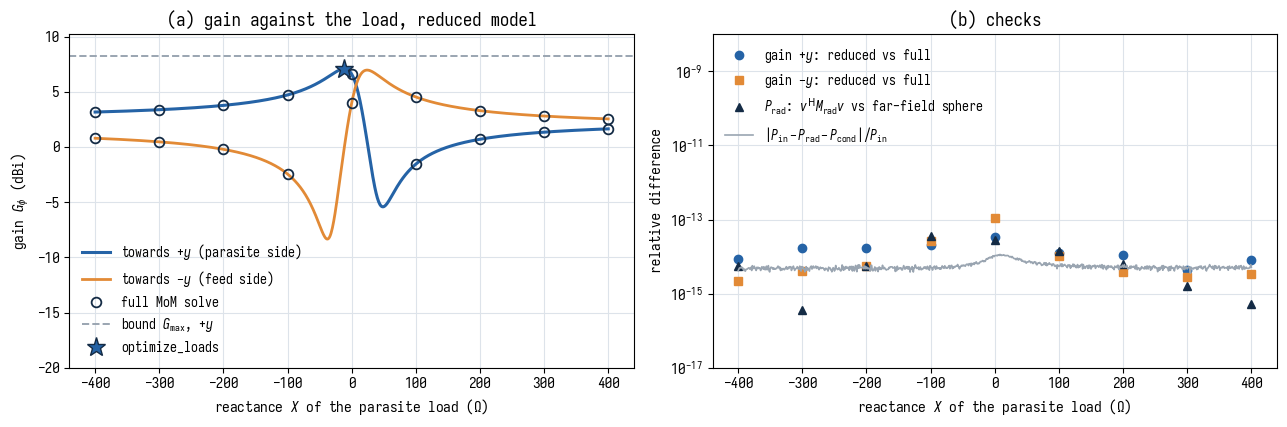

In [5]:
fig, (ax_g, ax_e) = plt.subplots(1, 2, figsize=(13, 4.4))
db = lambda g: 10 * np.log10(g)
ax_g.plot(X, db(G_p), color=BLUE, lw=2.2, label=r"towards $+y$ (parasite side)")
ax_g.plot(X, db(G_m), color=AMBER, lw=2.0, label=r"towards $-y$ (feed side)")
ax_g.plot([r["X"] for r in full], [db(r["G_p"]) for r in full], "o", mfc="none", mec=INK, ms=7, mew=1.3,
          label="full MoM solve")
ax_g.plot([r["X"] for r in full], [db(r["G_m"]) for r in full], "o", mfc="none", mec=INK, ms=7, mew=1.3)
ax_g.axhline(db(bound.g_max), color=GREY, ls="--", lw=1.4, label=r"bound $G_\mathrm{max}$, $+y$")
ax_g.plot(res.x_opt[0], db(res.G), "*", color=BLUE, mec=INK, ms=14, label="optimize_loads")
ax_g.set_xlabel(r"reactance $X$ of the parasite load ($\Omega$)")
ax_g.set_ylabel(r"gain $G_\phi$ (dBi)")
ax_g.set_title("(a) gain against the load, reduced model")
ax_g.set_ylim(-20, max(db(bound.g_max), db(G_p).max()) + 2)
ax_g.legend(frameon=False, fontsize=10, loc="lower left")

ax_e.semilogy([r["X"] for r in full], np.maximum([r["dG_p"] for r in full], 1e-17), "o", color=BLUE,
              label=r"gain $+y$: reduced vs full")
ax_e.semilogy([r["X"] for r in full], np.maximum([r["dG_m"] for r in full], 1e-17), "s", color=AMBER,
              label=r"gain $-y$: reduced vs full")
ax_e.semilogy([r["X"] for r in full], np.maximum([r["dP"] for r in full], 1e-17), "^", color=INK,
              label=r"$P_\mathrm{rad}$: $v^\mathsf{H} M_\mathrm{rad} v$ vs far-field sphere")
ax_e.semilogy(X, np.maximum(np.abs(resid), 1e-17), color=GREY, lw=1.2,
              label=r"$|P_\mathrm{in} - P_\mathrm{rad} - P_\mathrm{cond}| / P_\mathrm{in}$")
ax_e.set_ylim(1e-17, 1e-8)
ax_e.set_xlabel(r"reactance $X$ of the parasite load ($\Omega$)")
ax_e.set_ylabel("relative difference")
ax_e.set_title("(b) checks")
ax_e.legend(frameon=False, fontsize=10, loc="upper left")
for ax in (ax_g, ax_e):
    ax.grid(True, which="major", color="#dde3ea", lw=0.8)
fig.tight_layout()
fig.savefig(OUT_DIR / "reduced_multiport_load_sweep.svg", bbox_inches="tight", facecolor="white")
plt.show()

In [6]:
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

provenance = {
    "figure": "reduced_multiport_load_sweep.svg",
    "notebook": "documentation/figure_notebooks/theory_reduced_multiport.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "case": {"frequency_hz": FREQ, "length_m": LENGTH, "width_m": WIDTH, "spacing_m": SPACING,
             "n_len": N_LEN, "n_width": N_WIDTH, "edge_grading": "cosine", "conductivity_S_per_m": SIGMA,
             "zs_scale": model.zs_scale, "z_gen_ohm": Z_GEN, "n_edges": model.n_edges},
    "timings_s": {**{k: v for k, v in model.timings.items()}, "reduced_solve_per_load": t_per_solve,
                  "full_solve_per_load": t_full},
    "max_abs_power_balance_residual": float(np.max(np.abs(resid))),
    "full_solve_checks": full,
    "optimum_plus_y": {"x_opt_ohm": float(res.x_opt[0]), "element": res.element_label[0], "G": res.G,
                       "G_dBi": float(10 * np.log10(res.G)), "G_r": res.G_r, "D": res.D, "eta_rad": res.eta_rad,
                       "z_in": [res.z_in.real, res.z_in.imag], "n_evaluations": res.n_evaluations},
    "bound_plus_y": {"g_max": bound.g_max, "g_max_dBi": float(10 * np.log10(bound.g_max)), "cond_M": bound.cond},
}
(OUT_DIR / "reduced_multiport.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps({k: provenance[k] for k in ("timings_s", "optimum_plus_y", "bound_plus_y")}, indent=2))

{
  "timings_s": {
    "z_assembly": 12.482876800000668,
    "gram_assembly": 0.032524899987038225,
    "lu_factorization": 0.1829200999927707,
    "precompute": 0.006932899996172637,
    "reduced_solve_per_load": 6.891348314635483e-05,
    "full_solve_per_load": 0.11684419999882165
  },
  "optimum_plus_y": {
    "x_opt_ohm": -11.498507203719157,
    "element": "13.84 pF",
    "G": 5.11595575398048,
    "G_dBi": 7.089267797696307,
    "G_r": 3.196874722174734,
    "D": 5.312648422946581,
    "eta_rad": 0.9629765319842098,
    "z_in": [
      14.200257405750607,
      -20.573254240974094
    ],
    "n_evaluations": 135
  },
  "bound_plus_y": {
    "g_max": 6.625778150403639,
    "g_max_dBi": 8.21236890394644,
    "cond_M": 3668.678165652772
  }
}
